# Signal tutorial: what flows through a Lightstone graph

A hands-on walk along the reference link (PRBS13Q → driver → VCSEL → connector → 100 m OM4 → PIN → TIA → Bessel–Thomson → FFE → receiver output). At each wire we look at what the signal contains, and we recompute the conversions electrical → optical (VCSEL) and optical → electrical (PIN, TIA) by hand from what the engine reports.

Background and the full definitions: `docs/tutorial-signals-and-math.md` and `docs/signal-spec.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lightstone

g = lightstone.Graph.reference().run()
ports = g.ports()
for n in g.nodes():
    p = ports[n]
    ins = ", ".join(f"{i['name']}: {i['type']}" for i in p["inputs"]) or "—"
    outs = ", ".join(f"{o['name']}: {o['type']}" for o in p["outputs"]) or "—"
    print(f"{n:6s} {p['kind']:16s} {'linear' if p['linear'] else 'nonlinear/sink':15s} in [{ins}]  out [{outs}]")

src    prbs13q          linear          in [—]  out [out: data]
drv    driver           linear          in [in: data]  out [out: electrical (dimensionless)]
vcsel  vcsel            nonlinear/sink  in [in: electrical (dimensionless)]  out [out: optical]
el0    connector        linear          in [in: optical]  out [out: optical]
el1    mmf              linear          in [in: optical]  out [out: optical]
pin    pin              linear          in [in: optical]  out [out: electrical (current)]
tia    tia              linear          in [in: electrical (current)]  out [out: electrical (voltage)]
rxf    bessel_thomson   linear          in [in: electrical]  out [out: electrical]
ffe    ffe              linear          in [in: electrical, ref: data]  out [out: electrical]
rx     receiver_output  nonlinear/sink  in [in: electrical]  out [—]


## 1. Three signal types, one time grid

Every port has a type: **data** (symbols), **electrical** (a waveform tagged as drive, current or voltage) or **optical**. Wires only connect matching types. All signals share one **periodic** time grid: N = N_sym · sps samples at f_s = baud · sps, an integer number of pattern periods. Because everything is periodic, every filter is an exact circular convolution, i.e. a multiplication by H(f) on the FFT grid.

In [2]:
s = g.settings
n_sym = 8191 * s["pattern_periods"]
N = n_sym * s["sps"]
fs = s["baud"] * s["sps"]
print(f"baud {s['baud']/1e9:.3f} GBd, {s['sps']} samples/UI → fs = {fs/1e9:.0f} GS/s")
print(f"N = {n_sym} symbols × {s['sps']} = {N} samples, record {N/fs*1e9:.1f} ns")
print(f"FFT bin spacing Δf = fs/N = {fs/N/1e6:.2f} MHz (the PRBS line spacing), Nyquist {fs/2/1e9:.0f} GHz")
t = np.arange(N) / fs                                    # time axis [s]
f = np.fft.fftfreq(N, 1 / fs)                            # FFT-order frequencies [Hz]
sps = s["sps"]
ui = t * s["baud"]                                       # time in UI

baud 53.125 GBd, 16 samples/UI → fs = 850 GS/s
N = 8191 symbols × 16 = 131056 samples, record 154.2 ns
FFT bin spacing Δf = fs/N = 6.49 MHz (the PRBS line spacing), Nyquist 425 GHz


## 2. Data: the symbol stream

The pattern source outputs symbols only, no waveform and no noise. PRBS13Q has 8191 PAM-4 symbols, each level appearing almost equally often.

In [3]:
src = g.output("src")
sym = src["symbols"]
print(src["type"], "levels:", src["levels"], "first symbols:", sym[:20])
print("counts per level:", np.bincount(sym))

data levels: 4 first symbols: [1 1 1 1 1 1 2 2 2 2 2 2 1 3 2 1 3 2 2 0]
counts per level: [2047 2048 2048 2048]


## 3. Electrical: the drive

The driver turns symbols into a dimensionless drive waveform (quantity `drive`): each symbol holds its level for one UI, band-limited to the grid (the ripple at the edges is the Gibbs effect of an ideal NRZ spectrum). An electrical output always carries three arrays: `noiseless`, `signal` (noiseless + one noise realization) and `sigma` (the exact RMS noise vs. time). The driver adds no noise.

drive {'noiseless': (131056,), 'signal': (131056,), 'sigma': (131056,)} max σ: 0.0


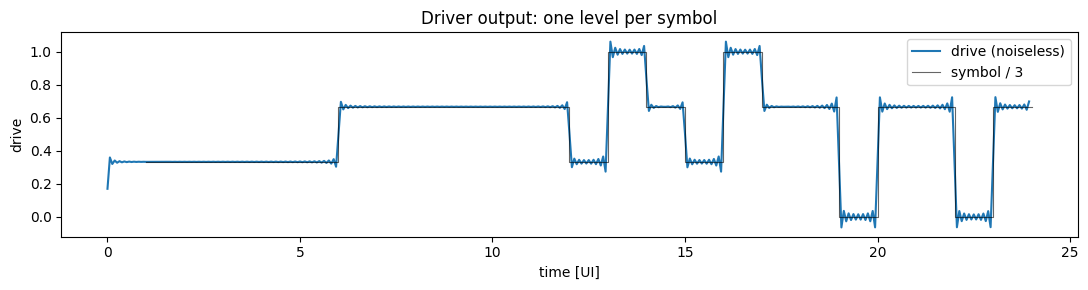

In [4]:
drv = g.output("drv")
print(drv["quantity"], {k: drv[k].shape for k in ("noiseless", "signal", "sigma")}, "max σ:", drv["sigma"].max())
k = slice(0, 24 * sps)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(ui[k], drv["noiseless"][k], label="drive (noiseless)")
ax.step(np.arange(24) + 1, sym[:24] / 3, where="pre", color="k", lw=0.8, alpha=0.6, label="symbol / 3")
ax.set(xlabel="time [UI]", ylabel="drive", title="Driver output: one level per symbol"); ax.legend(); plt.tight_layout()

## 4. Electrical → optical: the VCSEL

The VCSEL maps the drive to four optical power levels P₀…P₃ (set by average power and extinction ratio) and filters it with its modulation response (resonance f_r, damping ζ). The result is an **optical power** waveform in W. The VCSEL also defines the source's RIN (relative intensity noise), wavelength and spectral width. The port list above shows it as nonlinear: it clips the output power at 0 W (a laser cannot emit negative power), so the engine treats it as the point where the optical signal is created, not as a filter.

levels P0…P3 [mW]: [0.5695 0.8565 1.1435 1.4305]
average 1.0000 mW (= 0.00 dBm), ER 4.00 dB, OMA_outer 0.8610 mW, VCSEL bandwidth 28.3 GHz


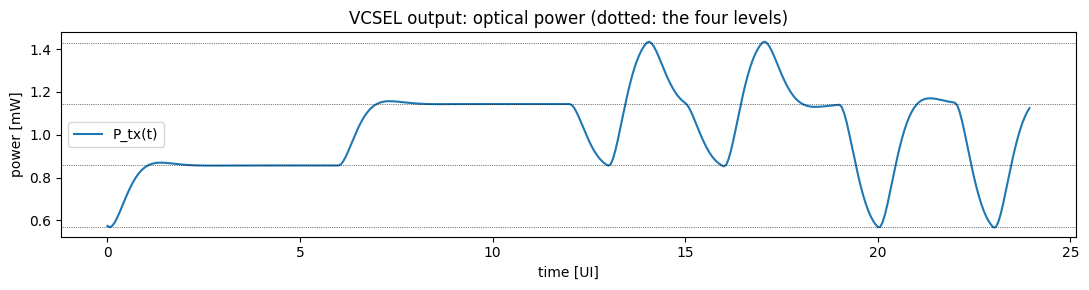

In [5]:
tx = g.report("vcsel")
P = np.array(tx["levels"])
print("levels P0…P3 [mW]:", np.round(P * 1e3, 4))
print(f"average {P.mean()*1e3:.4f} mW (= {10*np.log10(P.mean()/1e-3):.2f} dBm), ER {10*np.log10(P[3]/P[0]):.2f} dB, "
      f"OMA_outer {(P[3]-P[0])*1e3:.4f} mW, VCSEL bandwidth {tx['vcsel_bandwidth']/1e9:.1f} GHz")
p_tx = tx["power"]
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(ui[k], p_tx[k] * 1e3, label="P_tx(t)")
for p in P: ax.axhline(p * 1e3, color="k", lw=0.5, ls=":")
ax.set(xlabel="time [UI]", ylabel="power [mW]", title="VCSEL output: optical power (dotted: the four levels)"); ax.legend(); plt.tight_layout()

## 5. The optical wire is lazy

Asking the engine for the VCSEL's optical output gives only a summary: average power and the number of **source contributions** (one per laser feeding the wire). Internally an optical signal is *source + transfer function*: the transmitter spectrum plus, per **mode bin** (one fiber mode or mode group), a power weight w_k, a delay τ_k and a chromatic broadening σ_k. No per-mode waveform is ever stored while every block is linear.

In [6]:
for n in ("vcsel", "el0", "el1"):
    o = g.output(n)
    print(f"{n:6s} {o['type']}: average {o['average_power']*1e3:.4f} mW, {o['contributions']} contribution(s)")
fib = g.report("el1")
print(f"fiber: {fib['modes']} LP modes guided, V = {fib['v_number']:.1f}, launched fraction guided {fib['guided_fraction']:.5f}, "
      f"EMB {fib['emb_length']/1e9:.0f} MHz·km")

vcsel  optical: average 1.0001 mW, 1 contribution(s)
el0    optical: average 1.0001 mW, 1 contribution(s)
el1    optical: average 0.9226 mW, 1 contribution(s)
fiber: 90 LP modes guided, V = 37.0, launched fraction guided 0.99999, EMB 4710 MHz·km


### Inside the mode bins

The connector computes how much of the VCSEL's light lands in each mode (overlap integrals); the fiber gives each mode its delay. `lightstone.simulate()` runs the same reference link and exposes the per-mode data: `launched_power` (w_k), `relative_delay` (s/m) and `chromatic_slope` (s/m², the delay change per wavelength and length).

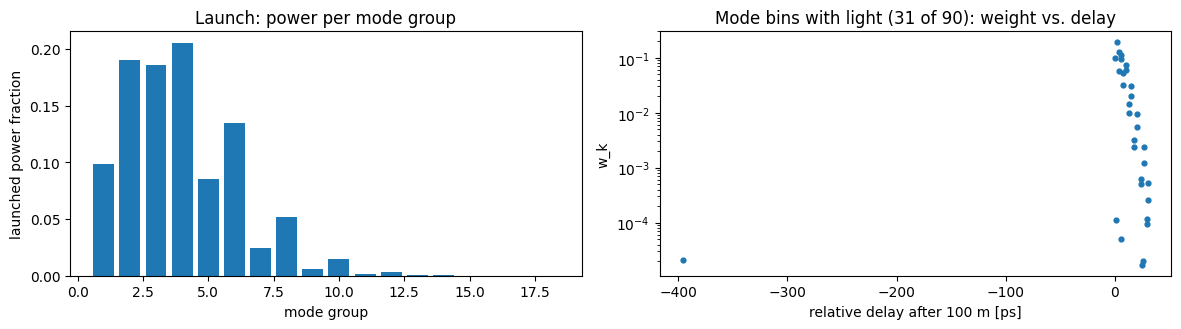

In [7]:
r = lightstone.simulate()
M = r.modes
grp = np.array([m["group"] for m in M]); w = np.array([m["launched_power"] for m in M])
L = 100.0
tau = np.array([m["relative_delay"] for m in M]) * L              # relative delay after 100 m [s]
sig = np.abs([m["chromatic_slope"] for m in M]) * L * 0.4e-9      # broadening σ_k for 0.4 nm RMS source [s]
groups = np.unique(grp)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(groups, [w[grp == q].sum() for q in groups]); ax[0].set(xlabel="mode group", ylabel="launched power fraction", title="Launch: power per mode group")
lit = w > 1e-5   # modes that received light (the highest groups get almost none)
ax[1].scatter(tau[lit] * 1e12, w[lit], s=12); ax[1].set_yscale("log")
ax[1].set(xlabel="relative delay after 100 m [ps]", ylabel="w_k", title=f"Mode bins with light ({lit.sum()} of {len(w)}): weight vs. delay")
plt.tight_layout()

Most of the light sits in the low mode groups, within about 30 ps of each other after 100 m; that spread is what limits the fiber's bandwidth. The single point near −400 ps is LP₁,₉ in group 18, the highest group, close to cutoff: its delay is far off, but it carries only 2 × 10⁻⁵ of the power.

### The fiber as a filter, recomputed by hand

At the photodiode the mode bins add up as power, so the fiber is one transfer function on power:

$$H_\text{fiber}(f) = T\sum_k w_k\,e^{-j2\pi f\tau_k}\,e^{-2\pi^2 f^2\sigma_k^2}$$

with T the attenuation. Applying it to the VCSEL waveform with one FFT must give the detected power that the PIN reports.

max |hand − engine| / max P = 1.1507207871987435e-11
fiber −3 dB bandwidth: 33.0 GHz (engine: 33.0 GHz)


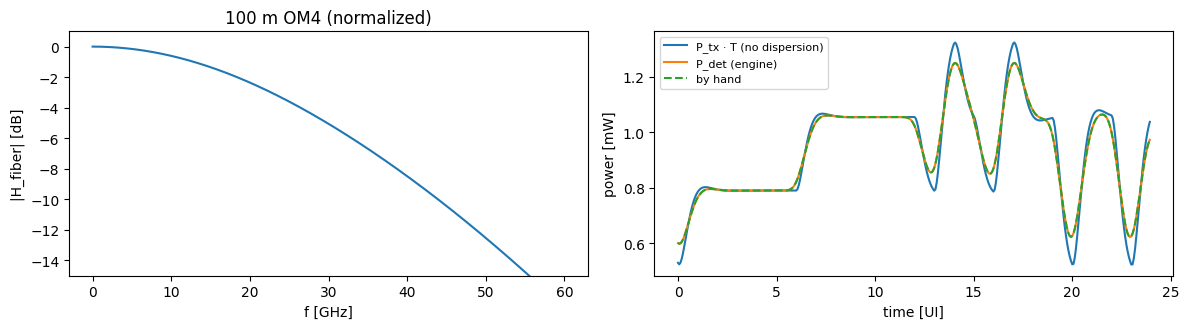

In [8]:
T = 10 ** (-3.5 * L / 1e3 / 10)          # OM4 preset: 3.5 dB/km
H = np.zeros(N, complex)
for wk, tk, sk in zip(w, tau, sig):
    H += wk * np.exp(-2j * np.pi * f * tk) * np.exp(-2 * np.pi**2 * f**2 * sk**2)
H *= T
mean_delay = np.sum(w * tau) / np.sum(w)                 # the engine removes the common delay
H *= np.exp(2j * np.pi * f * mean_delay)
p_hand = np.fft.ifft(np.fft.fft(p_tx) * H).real
p_det = g.report("pin")["p_det"]
print("max |hand − engine| / max P =", np.max(np.abs(p_hand - p_det)) / p_det.max())
fp = np.linspace(0, 60e9, 6001)
Hp = sum(wk * np.exp(-2j*np.pi*fp*tk) * np.exp(-2*np.pi**2*fp**2*sk**2) for wk, tk, sk in zip(w, tau, sig)) / w.sum()
print(f"fiber −3 dB bandwidth: {fp[np.argmax(np.abs(Hp) < 0.5)]/1e9:.1f} GHz (engine: {r.metrics['channel_bandwidth']/1e9:.1f} GHz)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(fp / 1e9, 20 * np.log10(np.abs(Hp))); ax[0].set(xlabel="f [GHz]", ylabel="|H_fiber| [dB]", ylim=(-15, 1), title="100 m OM4 (normalized)")
ax[1].plot(ui[k], p_tx[k] * T * 1e3, label="P_tx · T (no dispersion)"); ax[1].plot(ui[k], p_det[k] * 1e3, label="P_det (engine)")
ax[1].plot(ui[k], p_hand[k] * 1e3, "--", label="by hand"); ax[1].set(xlabel="time [UI]", ylabel="power [mW]"); ax[1].legend(fontsize=8)
plt.tight_layout()

The hand calculation reproduces the engine's detected power to about 10⁻¹¹: the optical wire really is just the source spectrum times this H(f).

## 6. Optical → electrical: PIN and TIA

The PIN photodiode turns detected optical power into a **current**, I = R · P_det (responsivity R in A/W). The TIA turns current into a **voltage**, V = Z · I (transimpedance Z in Ω). Both are linear, so the quantity tag changes (`current`, then `voltage`) but the signal stays an exact filter of the source.

In [9]:
R = g.params("pin")["responsivity"]; Z = g.params("tia")["transimpedance"]
i_pin = g.output("pin"); v_tia = g.output("tia")
print(f"PIN: quantity {i_pin['quantity']}, R = {R} A/W, max |I − R·P_det| = {np.max(np.abs(i_pin['noiseless'] - R*p_det)):.1e} A")
print(f"TIA: quantity {v_tia['quantity']}, Z = {Z:.0f} Ω, max |V − Z·I| = {np.max(np.abs(v_tia['noiseless'] - Z*i_pin['noiseless'])):.1e} V")
print(f"mean photocurrent {i_pin['noiseless'].mean()*1e3:.3f} mA → mean TIA output {v_tia['noiseless'].mean()*1e3:.1f} mV")

PIN: quantity current, R = 0.5 A/W, max |I − R·P_det| = 0.0e+00 A
TIA: quantity voltage, Z = 1000 Ω, max |V − Z·I| = 0.0e+00 V
mean photocurrent 0.461 mA → mean TIA output 461.3 mV


## 7. Noise is carried, not just added

Each electrical signal carries a list of noise terms (RIN from the VCSEL, shot noise from the PIN, thermal noise from the TIA), each a Gaussian source with its strength and the filter it has passed since. From that the engine computes the **exact** σ(t). Shot noise and RIN grow with the optical power, so σ(t) is larger on the upper levels; on this link RIN dominates. The `signal` array is one realization; its sample spread matches σ.

gaussian_exact = True;  RMS of (signal − noiseless) 7.206 mV, RMS σ(t) 7.264 mV


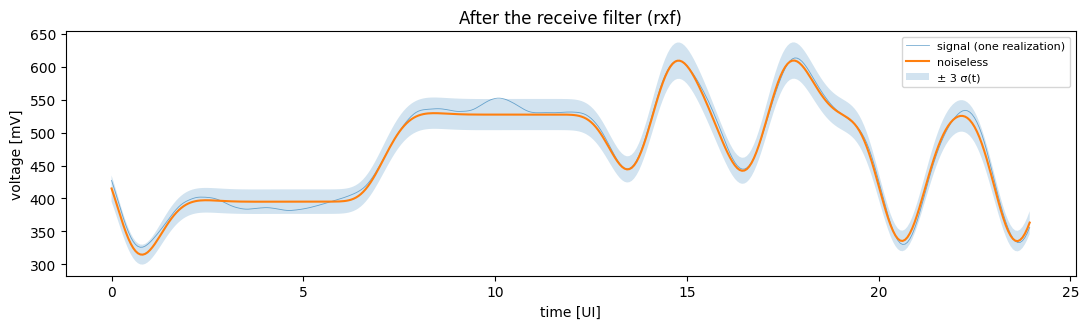

In [10]:
v = g.output("rxf")
y0, y, sg = v["noiseless"], v["signal"], v["sigma"]
print(f"gaussian_exact = {v['gaussian_exact']};  RMS of (signal − noiseless) {np.std(y - y0)*1e3:.3f} mV, "
      f"RMS σ(t) {np.sqrt(np.mean(sg**2))*1e3:.3f} mV")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ui[k], y[k] * 1e3, lw=0.6, alpha=0.6, label="signal (one realization)")
ax.plot(ui[k], y0[k] * 1e3, label="noiseless")
ax.fill_between(ui[k], (y0 - 3*sg)[k] * 1e3, (y0 + 3*sg)[k] * 1e3, alpha=0.2, label="± 3 σ(t)")
ax.set(xlabel="time [UI]", ylabel="voltage [mV]", title="After the receive filter (rxf)"); ax.legend(fontsize=8); plt.tight_layout()

### Which noise is where

Switching the sources off one at a time shows each contribution. The terms are independent Gaussians, so their variances add exactly: σ²_total = σ²_RIN + σ²_shot + σ²_thermal.

RMS σ [mV]: {'RIN': 6.512, 'shot': 2.027, 'thermal': 2.501} total 7.264
max |σ²_total − Σσ²_i| / max σ²_total = 8.691598479828304e-13


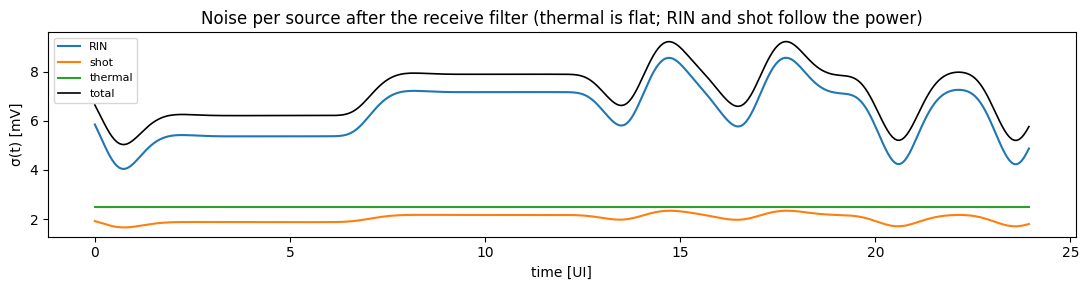

In [11]:
def sigma_rxf(rin=True, shot=True, thermal=True):
    h = lightstone.Graph.reference()
    h.set("vcsel", rin_enabled=rin).set("pin", shot_noise=shot).set("tia", thermal_noise=thermal).run()
    return h.output("rxf")["sigma"]

parts = {"RIN": sigma_rxf(True, False, False), "shot": sigma_rxf(False, True, False), "thermal": sigma_rxf(False, False, True)}
total = sg
print("RMS σ [mV]:", {kk: round(float(np.sqrt(np.mean(x**2))) * 1e3, 3) for kk, x in parts.items()}, "total", round(float(np.sqrt(np.mean(total**2)))*1e3, 3))
print("max |σ²_total − Σσ²_i| / max σ²_total =", np.max(np.abs(total**2 - sum(x**2 for x in parts.values()))) / np.max(total**2))
fig, ax = plt.subplots(figsize=(11, 3))
for kk, x in parts.items(): ax.plot(ui[k], x[k] * 1e3, label=kk)
ax.plot(ui[k], total[k] * 1e3, "k", lw=1.2, label="total")
ax.set(xlabel="time [UI]", ylabel="σ(t) [mV]", title="Noise per source after the receive filter (thermal is flat; RIN and shot follow the power)"); ax.legend(fontsize=8); plt.tight_layout()

## 8. In the frequency domain

The electrical spectrum analyzer shows the same two parts as spectra: the signal PSD (a PRBS line spectrum, averaged over the resolution bandwidth) and the noise PSD from the noise terms. The optical spectrum analyzer shows the source line at its wavelength and width.

ESA: signal RMS 107.9 mV, noise RMS 7.26 mV, SNR 23.4 dB, RBW 199 MHz


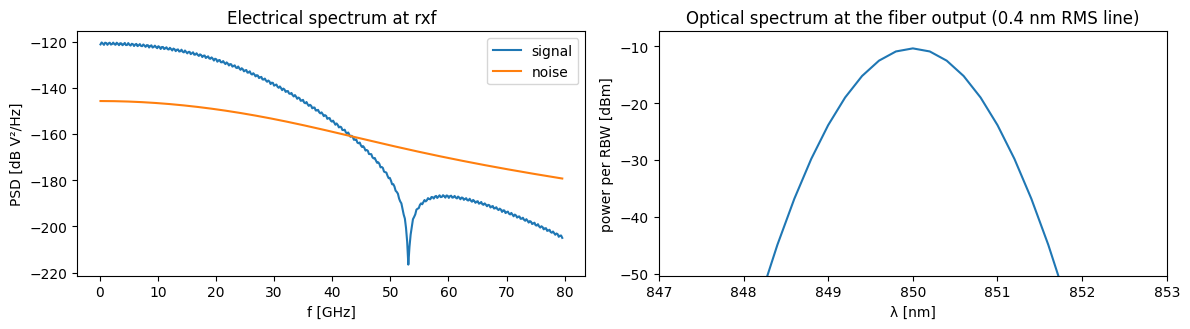

In [12]:
h = lightstone.Graph.reference()
h.add("esa", "electrical_spectrum_analyzer").wire("rxf", "esa")
h.add("osa", "optical_spectrum_analyzer").wire("el1", "osa").run()
esa, osa = h.report("esa"), h.report("osa")
print(f"ESA: signal RMS {esa['signal_rms']*1e3:.1f} mV, noise RMS {esa['noise_rms']*1e3:.2f} mV, SNR {esa['snr_db']:.1f} dB, RBW {esa['rbw']/1e6:.0f} MHz")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
fr = np.asarray(esa["frequency"])
ax[0].plot(fr / 1e9, esa["signal_db"], label="signal"); ax[0].plot(fr / 1e9, esa["noise_db"], label="noise")
ax[0].set(xlabel="f [GHz]", ylabel="PSD [dB V²/Hz]", title="Electrical spectrum at rxf"); ax[0].legend()
pk = max(osa["power_dbm"])
ax[1].plot(np.asarray(osa["wavelength"]) * 1e9, osa["power_dbm"])
ax[1].set(xlabel="λ [nm]", ylabel="power per RBW [dBm]", xlim=(847, 853), ylim=(pk - 40, pk + 3), title="Optical spectrum at the fiber output (0.4 nm RMS line)")
plt.tight_layout()

## 9. Linear vs. nonlinear

Everything so far was linear, so the engine only multiplied transfer functions and kept σ(t) exact (`gaussian_exact = True`). A level-dependent block breaks that. Clipping the TIA output cuts the noise tails: the engine then carries the noise as an explicit realization, `gaussian_exact` becomes False and the SER is counted (Monte Carlo) instead of computed.

TIA with clipping: gaussian_exact = False
SER 1.47e-03 via monte_carlo, resolution 1.2e-04
warnings: [('tia', 'TIA output clipped in 23.939 % of samples.'), ('rx', 'Noise has passed a nonlinear block, so σ(t) does not describe it and the semi-analytic SER is not valid. Use the counted (Monte Carlo) SER; it resolves SER ≳ 1.2e-4 with 8191 symbols.')]


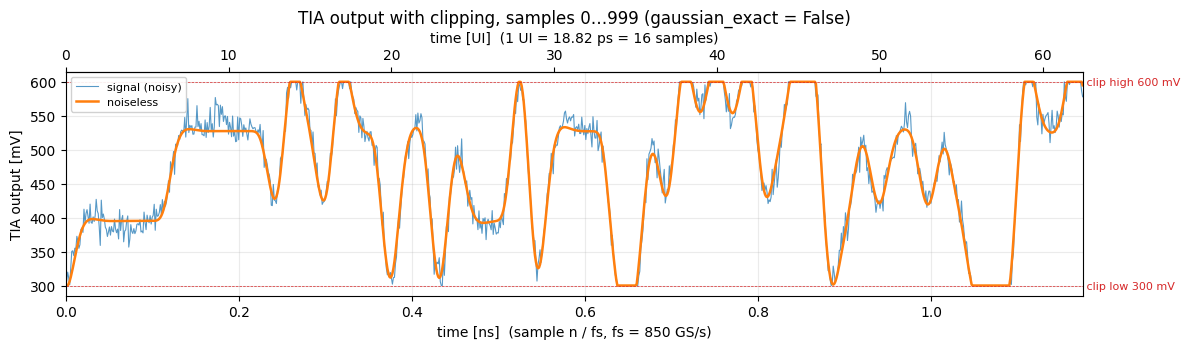

In [ ]:
c = lightstone.Graph.reference()
c.set("tia", clip=[0.30, 0.60]).run()
o = c.output("tia")
print("TIA with clipping: gaussian_exact =", o["gaussian_exact"])
a = c.receiver().analyze()
print(f"SER {a['ser']:.2e} via {a['ser_method']}, resolution {a['ser_resolution']:.1e}")
print("warnings:", c.warnings()[:2])

# TIA output with clipping: one noisy realization and the noiseless waveform (first 1000 samples).
lo, hi = 0.30, 0.60
n_show = 1000
t_ns = t[:n_show] * 1e9                                   # time of each sample [ns], t = n / fs
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t_ns, o["signal"][:n_show] * 1e3, color="C0", lw=0.8, alpha=0.75, label="signal (noisy)")
ax.plot(t_ns, o["noiseless"][:n_show] * 1e3, color="C1", lw=1.8, label="noiseless")
for y_, lab in ((hi, "clip high"), (lo, "clip low")):
    ax.axhline(y_ * 1e3, color="C3", ls="--", lw=1)
    ax.text(t_ns[-1], y_ * 1e3, f" {lab} {y_*1e3:.0f} mV", color="C3", va="center", ha="left", fontsize=8)
ax.set(xlabel=f"time [ns]  (sample n / fs, fs = {fs/1e9:.0f} GS/s)", ylabel="TIA output [mV]", xlim=(t_ns[0], t_ns[-1]),
       title=f"TIA output with clipping, samples 0…{n_show - 1} (gaussian_exact = False)")
# Second x-axis on top: the same time in unit intervals (1 UI = 1/baud = {sps} samples).
top = ax.secondary_xaxis("top", functions=(lambda x: x * 1e-9 * s["baud"], lambda u: u / s["baud"] * 1e9))
top.set_xlabel(f"time [UI]  (1 UI = {1e12/s['baud']:.2f} ps = {sps} samples)")
ax.grid(alpha=0.25)
ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
plt.tight_layout()

### Caching follows the signal flow

Each node's output is cached. Changing a parameter recomputes only that node and everything downstream.

In [14]:
g.set("el1", length=50.0).run(); print("fiber length changed:", g.computed_last_run, "of", len(g.nodes()), "nodes recomputed")
g.set("tia", transimpedance=800.0).run(); print("TIA gain changed:   ", g.computed_last_run, "of", len(g.nodes()), "nodes recomputed")

fiber length changed: 6 of 10 nodes recomputed
TIA gain changed:    4 of 10 nodes recomputed


## Summary

| Wire | Type / quantity | What it holds |
|---|---|---|
| src → drv | data | 8191 PAM-4 symbols, no noise |
| drv → vcsel | electrical, drive | band-limited NRZ drive (noiseless, signal, σ) |
| vcsel → fiber → pin | optical | lazy: source spectrum + per-mode-bin weight, delay, broadening; RIN as a noise source |
| pin → tia | electrical, current | I = R·P_det, plus shot noise |
| tia → rxf → ffe → rx | electrical, voltage | V = Z·I, plus thermal noise, each filter applied to signal and noise |

Electrical → optical happens in the VCSEL (drive → power levels → modulation response); optical → electrical in the PIN (power → current) and the TIA (current → voltage).